# Evaluación Sumativa 2. Validación, simulación y remuestreo
## Framingham Heart Study: riesgo de enfermedad coronaria a 10 años

MCDI501: Estadística Computacional para la Toma de Decisiones · Grupo 3

Este cuaderno **valida con métodos computacionales los resultados de nuestra Sumativa 1**: bootstrap (percentil y BCa) para los intervalos de confianza, test de permutación para las pruebas de hipótesis, estabilidad bootstrap de las correlaciones, una simulación Monte Carlo construida solo con parámetros estimados en S1 y un análisis de robustez ante valores extremos y supuestos. Cierra con un reporte de resultados validados que alimenta la Sumativa 3.

Todo el trabajo parte de los resultados propios de la Sumativa 1 (mismo dataset, misma semilla 42, mismas variables y mismos casos disponibles). Las secciones siguen el orden del informe.

## 0. Configuración, datos y resultados de la Sumativa 1
El dataset está versionado en `data/raw/framingham.csv` (ver `data/README.md`): la celda de carga verifica su huella SHA-256 y su forma (4.238 × 16) y se detiene si no coinciden, para que los resultados sean los mismos de S1. Solo si el archivo falta se descarga la versión 1 de Kaggle.

In [1]:
from pathlib import Path
import hashlib, platform, importlib.metadata
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
from scipy import stats

In [2]:
# Localizar el repositorio sin depender de rutas relativas ../../
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "requirements.txt").exists() and (p / "redaccion").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Abra el notebook dentro del repositorio del proyecto.")
CSV = ROOT / "data/raw/framingham.csv"   # copia versionada en el repositorio (ver data/README.md)
SHA_ESPERADO = "40921748dbdf6587045b9822414199a1ae3349358b63b975ab2208aa3cccc45b"
FORMA_ESPERADA = (4238, 16)
if not CSV.exists():   # solo si falta: se descarga la misma versión (1) de Kaggle
    import os, shutil
    os.environ["TQDM_DISABLE"] = "1"
    import warnings, io
    from contextlib import redirect_stdout
    with warnings.catch_warnings(), redirect_stdout(io.StringIO()):
        warnings.filterwarnings("ignore", message="IProgress not found.*")
        import kagglehub
        downloaded = kagglehub.dataset_download("dileep070/heart-disease-prediction-using-logistic-regression/versions/1")
    CSV.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(Path(downloaded) / "framingham.csv", CSV)
# Verificación: si el archivo no es la copia del proyecto, los resultados no serían comparables con los informes
sha = hashlib.sha256(CSV.read_bytes()).hexdigest()
forma = pd.read_csv(CSV).shape
if sha != SHA_ESPERADO or forma != FORMA_ESPERADA:
    raise ValueError(f"data/raw/framingham.csv no es la copia del proyecto (SHA-256 {sha[:12]}..., forma {forma}). "
                     "Restáurela con: git checkout -- data/raw/framingham.csv")
print(f"Dataset verificado: data/raw/framingham.csv | {forma[0]:,} filas x {forma[1]} columnas".replace(",", "."))
print("SHA-256:", sha)
display(pd.DataFrame({"Componente": ["Python", "numpy", "pandas", "scipy", "matplotlib"],
    "Versión": [platform.python_version(), *[importlib.metadata.version(p)
                 for p in ["numpy", "pandas", "scipy", "matplotlib"]]]}))

Dataset verificado: data/raw/framingham.csv | 4.238 filas x 16 columnas
SHA-256: 40921748dbdf6587045b9822414199a1ae3349358b63b975ab2208aa3cccc45b


,Componente,Versión
0,Python,3.13.15
1,numpy,2.5.3
2,pandas,3.0.5
3,scipy,1.18.1
4,matplotlib,3.11.1


In [3]:
SEED = 42
B = 10_000                    # remuestras bootstrap, permutaciones e iteraciones Monte Carlo
TARGET = "TenYearCHD"
ALPHA = 0.05
df = pd.read_csv(CSV)
n = len(df)
pd.set_option("display.max_columns", None)

FIGURAS = ROOT / "redaccion/sumativa-2-validacion-simulacion-remuestreo/figuras"
SALIDA = ROOT / "informes/sumativa-2-validacion-simulacion-remuestreo"
FIGURAS.mkdir(parents=True, exist_ok=True); SALIDA.mkdir(parents=True, exist_ok=True)

# Misma paleta y estilo que la Sumativa 1
NAVY, RED, GREY, BG, OCHRE = "#0d2741", "#ae0000", "#8c8578", "#f6f1ea", "#c0852f"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.facecolor": BG,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#ddd5c6", "axes.axisbelow": True,
})
def fmt_es(x, dec=1):
    """Número con formato español: coma decimal y punto de miles."""
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")
def eje_es(ax, eje="x", dec=1):
    f = FuncFormatter(lambda v, _: fmt_es(v, dec))
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(f)
print("Filas y columnas:", df.shape, "| Semilla:", SEED, "| B =", f"{B:,}")

Filas y columnas: (4238, 16) | Semilla: 42 | B = 10,000


In [4]:
# Resultados de la Sumativa 1 que se validan (IC clásicos al 95%, calculados igual que en S1)
z = stats.norm.ppf(0.975)
def ic_t(x):
    m, ee = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    c = stats.t.ppf(0.975, df=len(x) - 1)
    return m, m - c * ee, m + c * ee

PARAMS = {}    # parámetro -> datos, estimación y IC clásico de S1
for clave, nombre, col in [("edad", "Edad media (años)", "age"),
                           ("colesterol", "Colesterol total medio (mg/dL)", "totChol"),
                           ("pas", "Presión sistólica media (mmHg)", "sysBP")]:
    x = df[col].dropna().to_numpy(float)
    m, lo, hi = ic_t(x)
    PARAMS[clave] = dict(nombre=nombre, x=x, est=m, lo=lo, hi=hi, metodo="t de Student", stat=np.mean)
xb = df[TARGET].to_numpy(float); k = int(xb.sum())
w = stats.binomtest(k, len(xb)).proportion_ci(confidence_level=0.95, method="wilson")
PARAMS["chd"] = dict(nombre="Proporción de CHD a 10 años", x=xb, est=xb.mean(), lo=w.low, hi=w.high,
                     metodo="Wilson", stat=np.mean)
xm = PARAMS["colesterol"]["x"]
PARAMS["mediana_col"] = dict(nombre="Mediana del colesterol (mg/dL)", x=xm, est=np.median(xm), lo=np.nan, hi=np.nan,
                             metodo="sin IC clásico", stat=np.median)

tabla_s1 = pd.DataFrame([{"Parámetro": p["nombre"], "Estimación": p["est"], "IC clásico inf.": p["lo"],
                          "IC clásico sup.": p["hi"], "n": len(p["x"]), "Método S1": p["metodo"]}
                         for p in PARAMS.values()]).round(3)
tabla_s1

,Parámetro,Estimación,IC clásico inf.,IC clásico sup.,n,Método S1
0,Edad media (años),49.585,49.327,49.843,4238,t de Student
1,Colesterol total medio (mg/dL),236.722,235.371,238.072,4188,t de Student
2,Presión sistólica media (mmHg),132.352,131.689,133.016,4238,t de Student
3,Proporción de CHD a 10 años,0.152,0.141,0.163,4238,Wilson
4,Mediana del colesterol (mg/dL),234.000,NaN,NaN,4188,sin IC clásico


## 1. Validación con bootstrap: percentil y BCa frente al IC clásico

Para cada parámetro de la Sumativa 1 generamos **10.000 remuestras** con reemplazo (no paramétrico) y construimos el IC al 95% con tres métodos: normal (error estándar bootstrap), percentil y BCa (con corrección de sesgo $z_0$ y aceleración $a$ por jackknife), siguiendo el apunte del curso. Se comparan con el IC clásico de S1. Como control de la implementación, el BCa propio se contrasta con `scipy.stats.bootstrap`. La mediana del colesterol se agrega como parámetro extra porque no tiene fórmula clásica sencilla y es la medida que S1 recomendó para variables asimétricas.

In [5]:
rng = np.random.default_rng(SEED)   # sección reproducible

def replicas(x, stat, B, rng, lote=250):
    """B réplicas bootstrap del estadístico (remuestreo no paramétrico con reemplazo)."""
    nn = len(x); out = np.empty(B)
    for i in range(0, B, lote):
        b = min(lote, B - i)
        out[i:i + b] = stat(x[rng.integers(0, nn, size=(b, nn))], axis=1)
    return out

def jackknife(x, stat):
    if stat is np.mean:
        return (x.sum() - x) / (len(x) - 1)            # forma cerrada
    return np.array([stat(np.delete(x, i)) for i in range(len(x))])

def ic_percentil(reps):
    return tuple(np.percentile(reps, [2.5, 97.5]))

def ic_normal(theta, reps):
    se = reps.std(ddof=1)
    return theta - z * se, theta + z * se

def ic_bca(theta, reps, jack, alpha=0.05):
    # z0 con corrección por empates (réplicas iguales a theta cuentan la mitad)
    prop = (np.mean(reps < theta) + 0.5 * np.mean(reps == theta))
    z0 = stats.norm.ppf(np.clip(prop, 1e-10, 1 - 1e-10))
    d = jack.mean() - jack
    den = 6.0 * ((d ** 2).sum()) ** 1.5
    a = (d ** 3).sum() / den if den != 0 else 0.0     # jackknife degenerado (p. ej. mediana con empates): a = 0
    za, zb = stats.norm.ppf(alpha / 2), stats.norm.ppf(1 - alpha / 2)
    a1 = stats.norm.cdf(z0 + (z0 + za) / (1 - a * (z0 + za)))
    a2 = stats.norm.cdf(z0 + (z0 + zb) / (1 - a * (z0 + zb)))
    return tuple(np.percentile(reps, [100 * a1, 100 * a2])), z0, a

filas, BOOT = [], {}
for clave, p in PARAMS.items():
    x, th, stat = p["x"], p["est"], p["stat"]
    reps = replicas(x, stat, B, rng)
    jack = jackknife(x, stat)
    pc = ic_percentil(reps); nm = ic_normal(th, reps); bc, z0, a = ic_bca(th, reps, jack)
    # control: BCa de scipy (otro flujo aleatorio, mismas B)
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # scipy avisa cuando el BCa es indefinido (mediana con empates)
        try:
            sc = stats.bootstrap((x,), stat, n_resamples=B, method="BCa", vectorized=True,
                                 random_state=np.random.default_rng(SEED)).confidence_interval
        except Exception:
            from types import SimpleNamespace as _NS; sc = _NS(low=np.nan, high=np.nan)
    BOOT[clave] = dict(reps=reps, pc=pc, nm=nm, bc=bc, z0=z0, a=a, se=reps.std(ddof=1), sc=(sc.low, sc.high))
    metodos = [("Normal", nm), ("Percentil", pc), ("BCa", bc), ("BCa (scipy)", (sc.low, sc.high))]
    if not np.isnan(p["lo"]):
        metodos.insert(0, (f"Clásico ({p['metodo']})", (p["lo"], p["hi"])))
    esc = 100 if clave == "chd" else 1
    for nombre_m, (lo, hi) in metodos:
        filas.append({"Parámetro": p["nombre"], "Método": nombre_m, "Estimación": th * esc,
                      "IC inf.": lo * esc, "IC sup.": hi * esc, "Amplitud": (hi - lo) * esc,
                      "Asimetría": abs((hi - th) - (th - lo)) * esc})
    print(f"{p['nombre']:34s} θ̂={th*esc:9.3f}  SE boot={reps.std(ddof=1)*esc:.4f}  z0={z0:+.4f}  a={a:+.5f}")
tabla_boot = pd.DataFrame(filas)
for par, g in tabla_boot.groupby("Parámetro", sort=False):
    print("\n" + par); display(g.drop(columns="Parámetro").round(3).reset_index(drop=True))

Edad media (años)                  θ̂=   49.585  SE boot=0.1323  z0=+0.0024  a=+0.00058


Colesterol total medio (mg/dL)     θ̂=  236.722  SE boot=0.6837  z0=+0.0068  a=+0.00224


Presión sistólica media (mmHg)     θ̂=  132.352  SE boot=0.3354  z0=+0.0120  a=+0.00293


Proporción de CHD a 10 años        θ̂=   15.196  SE boot=0.5556  z0=-0.0085  a=+0.00496


Mediana del colesterol (mg/dL)     θ̂=  234.000  SE boot=0.8875  z0=+0.3124  a=+0.00000

Edad media (años)


...

,Método,Estimación,IC inf.,IC sup.,Amplitud,Asimetría
0,Clásico (t de Student),132.352,131.689,133.016,1.327,0.000
1,Normal,132.352,131.695,133.010,1.315,0.000
2,Percentil,132.352,131.695,133.013,1.318,0.004
3,BCa,132.352,131.707,133.031,1.325,0.033
4,BCa (scipy),132.352,131.690,133.023,1.333,0.008



Proporción de CHD a 10 años


,Método,Estimación,IC inf.,IC sup.,Amplitud,Asimetría
0,Clásico (Wilson),15.196,14.147,16.308,2.162,0.063
1,Normal,15.196,14.107,16.285,2.178,0.000
2,Percentil,15.196,14.134,16.305,2.171,0.047
3,BCa,15.196,14.134,16.305,2.171,0.047
4,BCa (scipy),15.196,14.158,16.328,2.171,0.094



Mediana del colesterol (mg/dL)


,Método,Estimación,IC inf.,IC sup.,Amplitud,Asimetría
0,Normal,234.0,232.26,235.74,3.479,0.0
1,Percentil,234.0,232.00,235.00,3.000,1.0
2,BCa,234.0,232.00,236.00,4.000,0.0
3,BCa (scipy),234.0,NaN,NaN,NaN,NaN


In [6]:
# Diferencias entre el BCa propio y el de scipy (control de implementación)
ctrl = pd.DataFrame([{"Parámetro": PARAMS[c]["nombre"],
                      "Dif. máx. de límites (BCa propio vs scipy)": max(abs(BOOT[c]["bc"][0] - BOOT[c]["sc"][0]),
                                                                          abs(BOOT[c]["bc"][1] - BOOT[c]["sc"][1])),
                      "Como % de la amplitud": 100 * max(abs(BOOT[c]["bc"][0] - BOOT[c]["sc"][0]),
                                                          abs(BOOT[c]["bc"][1] - BOOT[c]["sc"][1]))
                                               / (BOOT[c]["bc"][1] - BOOT[c]["bc"][0])} for c in PARAMS])
display(ctrl.round(4))

,Parámetro,Dif. máx. de límites (BCa propio vs scipy),Como % de la amplitud
0,Edad media (años),0.0000,0.0000
1,Colesterol total medio (mg/dL),0.0412,1.5380
2,Presión sistólica media (mmHg),0.0169,1.2736
3,Proporción de CHD a 10 años,0.0002,1.0870
4,Mediana del colesterol (mg/dL),NaN,NaN


### Figura 1. Distribuciones bootstrap y comparación de intervalos

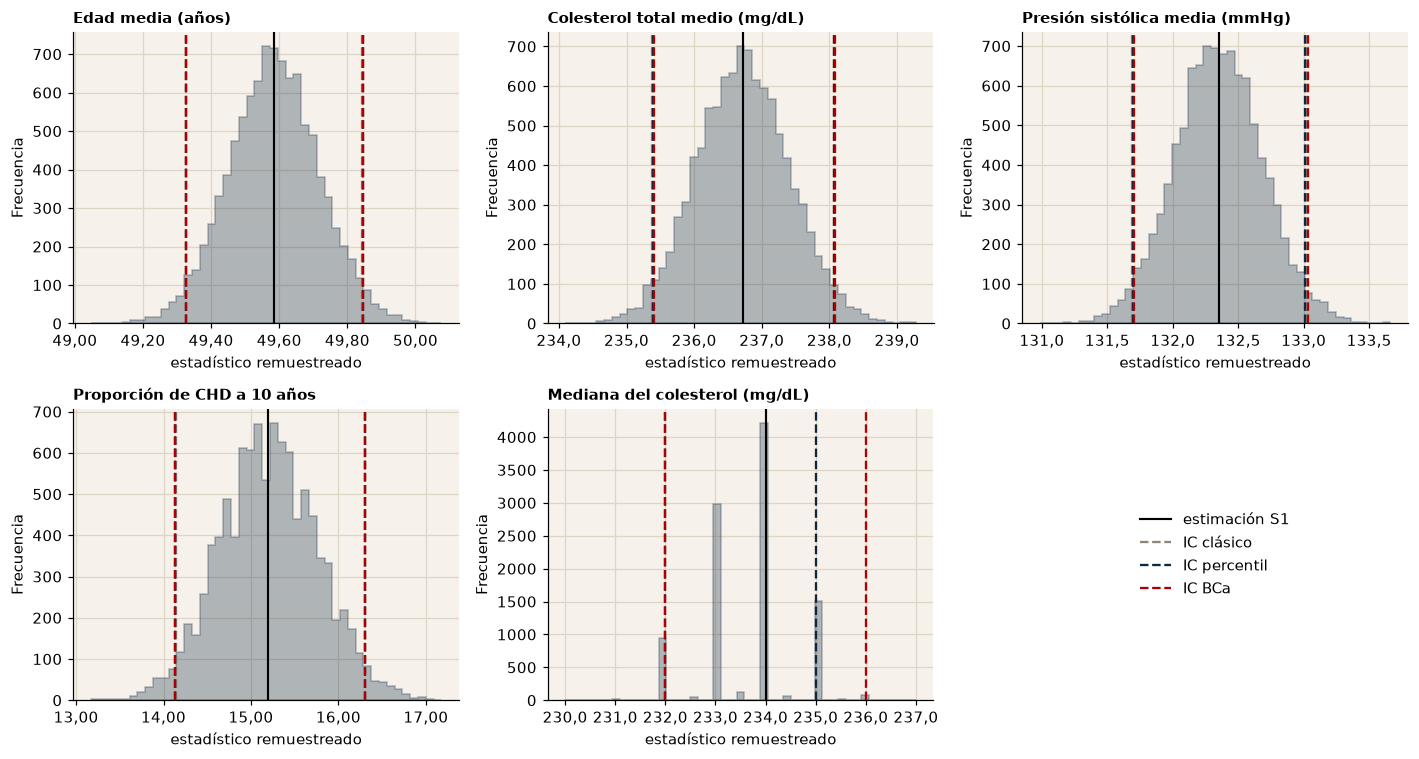

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
orden = ["edad", "colesterol", "pas", "chd", "mediana_col"]
for ax, c in zip(axs.ravel(), orden):
    p, bt = PARAMS[c], BOOT[c]
    esc = 100 if c == "chd" else 1
    ax.hist(bt["reps"] * esc, bins=45, color=NAVY, alpha=0.30, edgecolor=NAVY, linewidth=1.0, histtype="stepfilled")
    cl = [(p["lo"], p["hi"], GREY)] if not np.isnan(p["lo"]) else []
    for lo, hi, col in cl + [(*bt["pc"], NAVY), (*bt["bc"], RED)]:
        ax.axvline(lo * esc, color=col, lw=1.5, ls="--"); ax.axvline(hi * esc, color=col, lw=1.5, ls="--")
    ax.axvline(p["est"] * esc, color="black", lw=1.4)
    ax.set_title(p["nombre"], fontsize=10); eje_es(ax, "x", 2 if c in ("edad", "chd") else 1)
    ax.set_xlabel("estadístico remuestreado"); ax.set_ylabel("Frecuencia")
axs[1, 2].axis("off")
leg = [Line2D([0], [0], color="black", lw=1.4, label="estimación S1"),
       Line2D([0], [0], color=GREY, ls="--", label="IC clásico"),
       Line2D([0], [0], color=NAVY, ls="--", label="IC percentil"),
       Line2D([0], [0], color=RED, ls="--", label="IC BCa")]
axs[1, 2].legend(handles=leg, loc="center", frameon=False, fontsize=10)
plt.tight_layout(); plt.savefig(FIGURAS / "fig_bootstrap.png", bbox_inches="tight"); plt.show()

**Lectura.** En las tres medias y en la proporción de CHD, los intervalos clásico, percentil y BCa prácticamente coinciden: los límites difieren en centésimas (edad: clásico [49,33; 49,84] y BCa [49,33; 49,85]; colesterol: [235,37; 238,07] y [235,41; 238,08]; presión sistólica: [131,69; 133,02] y [131,71; 133,03]; proporción de CHD: Wilson [14,15 %; 16,31 %] y BCa [14,13 %; 16,30 %]). El BCa se aparta del clásico entre 0,6 % y 1,4 % de la amplitud del intervalo. Los factores de corrección son pequeños (|$z_0$| ≤ 0,012 y $a$ ≤ 0,005): casi no hay sesgo ni asimetría que corregir, porque con unas 4.200 observaciones el Teorema Central del Límite ya funciona, incluso en el colesterol (asimetría 0,87). El BCa propio y el de `scipy` difieren en menos de 1,5 % de la amplitud, lo que valida la implementación.

**Cómo leer estos intervalos.** El 95 % describe el **procedimiento**, no un intervalo en particular: si se repitiera el muestreo muchas veces y en cada muestra se calculara un intervalo con el mismo método, alrededor del 95 % de esos intervalos contendría el verdadero valor del parámetro, que es fijo. No se afirma que cada intervalo concreto contenga el parámetro con probabilidad 0,95.

**Confiabilidad según los supuestos.** El clásico exige media muestral aproximadamente normal (TCL) e independencia; el percentil supone una distribución bootstrap simétrica y sin sesgo; el BCa corrige sesgo y asimetría, pero es más costoso y sensible a valores extremos. Como los tres coinciden, **los intervalos de S1 quedan validados**; ninguno de los métodos puede comprobar la independencia entre participantes, que sigue siendo un supuesto.

**Mediana del colesterol (parámetro extra).** No tiene IC clásico simple: percentil [232; 235] y BCa [232; 236]. Los intervalos son toscos porque el colesterol se mide en valores enteros y la distribución bootstrap de la mediana toma muy pocos valores distintos. Con empates en los valores centrales el jackknife se vuelve degenerado ($a$ = 0) y `scipy` no logra calcular el BCa; por eso la mediana se informa con cautela.

## 2. Validación de pruebas de hipótesis mediante permutación

Validamos la **prueba t de Welch de S1** (diferencia de edad entre quienes desarrollan CHD y quienes no) con un test de permutación de 10.000 repeticiones: si la edad no se relacionara con el CHD, reasignar al azar las etiquetas de grupo no debería cambiar la diferencia. Se permuta la diferencia de medias (estadístico observado) y, además, el estadístico t de Welch estudentizado, para comparar la distribución nula con la teórica. Como segunda validación, se permuta el χ² de la prueba de hipertensión prevalente y CHD.

In [8]:
rng = np.random.default_rng(SEED)   # sección reproducible
edad = df["age"].to_numpy(float); y = df[TARGET].to_numpy(int)
n1 = int(y.sum()); n0 = len(y) - n1; tot, tot2 = edad.sum(), (edad ** 2).sum()

def dif_y_t(s1, ss1):
    """Diferencia de medias y t de Welch a partir de sumas del grupo 1 (el resto sale del total)."""
    s0, ss0 = tot - s1, tot2 - ss1
    m1, m0 = s1 / n1, s0 / n0
    v1, v0 = (ss1 - s1 ** 2 / n1) / (n1 - 1), (ss0 - s0 ** 2 / n0) / (n0 - 1)
    return m1 - m0, (m1 - m0) / np.sqrt(v1 / n1 + v0 / n0)

obs_dif, obs_t = dif_y_t(edad[y == 1].sum(), (edad[y == 1] ** 2).sum())
perm_dif, perm_t = np.empty(B), np.empty(B)
for j in range(B):
    idx = rng.permutation(len(y))[:n1]
    perm_dif[j], perm_t[j] = dif_y_t(edad[idx].sum(), (edad[idx] ** 2).sum())

p_dif = (np.sum(np.abs(perm_dif) >= abs(obs_dif)) + 1) / (B + 1)
p_t = (np.sum(np.abs(perm_t) >= abs(obs_t)) + 1) / (B + 1)
welch = stats.ttest_ind(edad[y == 1], edad[y == 0], equal_var=False)

print(f"Diferencia observada (CHD - sin CHD) = {obs_dif:.3f} años;  t de Welch observado = {obs_t:.2f}")
print(f"Distribución nula de la diferencia: rango [{perm_dif.min():.3f}, {perm_dif.max():.3f}], sd = {perm_dif.std():.3f}")
print(f"Permutaciones con |dif| >= observada: {int(np.sum(np.abs(perm_dif) >= abs(obs_dif)))} de {B:,}")
print(f"p de permutación (diferencia de medias) = {p_dif:.5f}   (cota mínima alcanzable = 1/(B+1) = {1/(B+1):.5f})")
print(f"p de permutación (t de Welch)           = {p_t:.5f}")
print(f"p paramétrico de S1 (Welch)             = {welch.pvalue:.2e}  (t = {welch.statistic:.2f}, gl = {welch.df:.0f})")
print(f"\nDistribución nula del t permutado: media = {perm_t.mean():+.4f}, sd = {perm_t.std():.4f} (teórico N(0,1): 0 y 1)")
print("Cuantiles 2.5% y 97.5% del t permutado:", np.percentile(perm_t, [2.5, 97.5]).round(3),
      " frente a ±", round(stats.t.ppf(0.975, welch.df), 3), "de la t teórica")

Diferencia observada (CHD - sin CHD) = 5.378 años;  t de Welch observado = 15.58
Distribución nula de la diferencia: rango [-1.267, 1.372], sd = 0.370
Permutaciones con |dif| >= observada: 0 de 10,000
p de permutación (diferencia de medias) = 0.00010   (cota mínima alcanzable = 1/(B+1) = 0.00010)
p de permutación (t de Welch)           = 0.00010
p paramétrico de S1 (Welch)             = 1.04e-48  (t = 15.58, gl = 916)

Distribución nula del t permutado: media = +0.0040, sd = 1.0090 (teórico N(0,1): 0 y 1)
Cuantiles 2.5% y 97.5% del t permutado: [-1.954  2.001]  frente a ± 1.963 de la t teórica


In [9]:
# Segunda validación: hipertensión prevalente vs CHD (χ² de S1)
rng = np.random.default_rng(SEED)   # sección reproducible
hip = df["prevalentHyp"].to_numpy(int)
def chi2_stat(h, yy):
    a = np.sum((h == 1) & (yy == 1)); b = np.sum((h == 1) & (yy == 0))
    c = np.sum((h == 0) & (yy == 1)); d = np.sum((h == 0) & (yy == 0))
    N = a + b + c + d
    return N * (a * d - b * c) ** 2 / ((a + b) * (c + d) * (a + c) * (b + d))
obs_chi = chi2_stat(hip, y)
perm_chi = np.array([chi2_stat(hip, rng.permutation(y)) for _ in range(B)])
p_chi = (np.sum(perm_chi >= obs_chi) + 1) / (B + 1)
tabla = pd.crosstab(df["prevalentHyp"], df[TARGET])
chi_yates = stats.chi2_contingency(tabla)
print(f"χ² observado (sin corrección) = {obs_chi:.1f};  con Yates (S1) = {chi_yates[0]:.1f},  p paramétrico = {chi_yates[1]:.2e}")
print(f"Distribución nula permutada: máx = {perm_chi.max():.2f},  media = {perm_chi.mean():.3f} (teórico χ²(1): media 1)")
print(f"Permutaciones con χ² >= observado: {int(np.sum(perm_chi >= obs_chi))} de {B:,};  p de permutación = {p_chi:.5f}")
print("Cuantil 95% de la nula permutada:", np.percentile(perm_chi, 95).round(3), " frente a χ²(1) teórico:", round(stats.chi2.ppf(0.95, 1), 3))

χ² observado (sin corrección) = 133.7;  con Yates (S1) = 132.6,  p paramétrico = 1.10e-30
Distribución nula permutada: máx = 16.57,  media = 1.003 (teórico χ²(1): media 1)
Permutaciones con χ² >= observado: 0 de 10,000;  p de permutación = 0.00010
Cuantil 95% de la nula permutada: 3.78  frente a χ²(1) teórico: 3.841


### Figura 2. Distribución nula de permutación

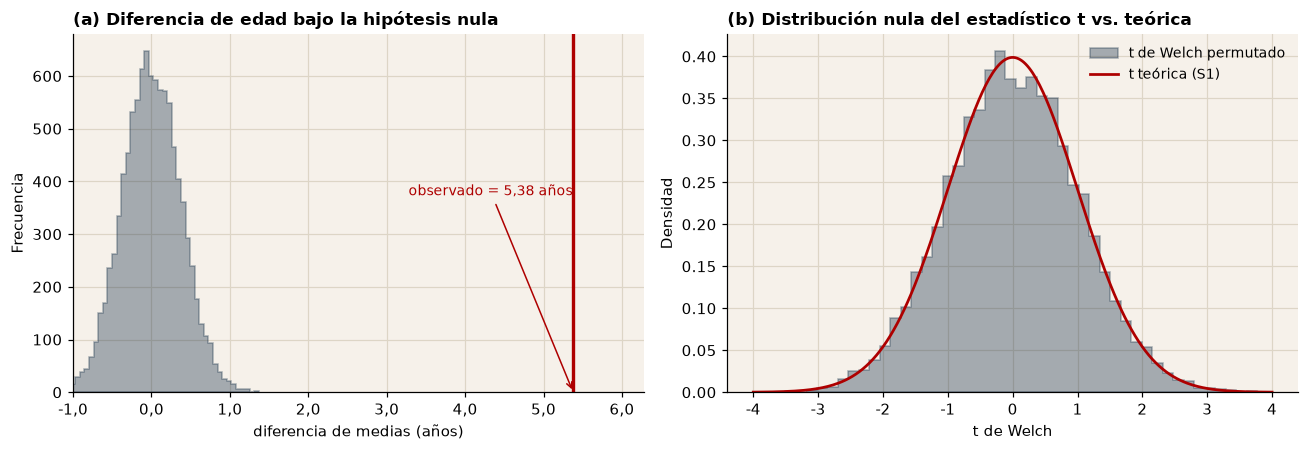

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(perm_dif, bins=45, color=NAVY, alpha=0.35, edgecolor=NAVY, linewidth=1.0, histtype="stepfilled")
ax[0].axvline(obs_dif, color=RED, lw=2.2)
ax[0].annotate(f"observado = {fmt_es(obs_dif, 2)} años", xy=(obs_dif, 0), xytext=(obs_dif - 2.1, ax[0].get_ylim()[1] * 0.55),
               color=RED, fontsize=9, arrowprops=dict(arrowstyle="->", color=RED))
ax[0].set_xlim(-1.0, obs_dif + 0.9); eje_es(ax[0], "x", 1)
ax[0].set_title("(a) Diferencia de edad bajo la hipótesis nula")
ax[0].set_xlabel("diferencia de medias (años)"); ax[0].set_ylabel("Frecuencia")
ax[1].hist(perm_t, bins=45, density=True, color=NAVY, alpha=0.35, edgecolor=NAVY, linewidth=1.0, histtype="stepfilled",
           label="t de Welch permutado")
xs = np.linspace(-4, 4, 300)
ax[1].plot(xs, stats.t.pdf(xs, welch.df), color=RED, lw=1.8, label="t teórica (S1)")
ax[1].set_title("(b) Distribución nula del estadístico t vs. teórica")
ax[1].set_xlabel("t de Welch"); ax[1].set_ylabel("Densidad"); ax[1].legend(frameon=False, fontsize=9); eje_es(ax[1], "x", 0)
plt.tight_layout(); plt.savefig(FIGURAS / "fig_permutacion.png", bbox_inches="tight"); plt.show()

**Lectura (edad y CHD).** La diferencia observada es de 5,38 años (mayor edad en quienes desarrollan CHD). Si la edad no estuviera asociada con el CHD, reasignar las etiquetas al azar produce diferencias centradas en cero (desviación estándar 0,37 años, rango de −1,27 a 1,37). **Ninguna de las 10.000 permutaciones** alcanza el valor observado, de modo que el valor p de permutación es 0,0001, que es la cota mínima posible con 10.000 repeticiones (1/(B+1)). El valor p paramétrico de S1 es 1,0 × 10⁻⁴⁸. Los dos enfoques concuerdan en la decisión (se rechaza $H_0$); sus magnitudes no son comparables porque la permutación no puede informar valores p más pequeños que 1/(B+1).

**Concordancia de la distribución nula.** El estadístico t de Welch permutado tiene media 0,004 y desviación estándar 1,009, y sus cuantiles 2,5 % y 97,5 % son −1,95 y 2,00, frente a ±1,96 de la distribución teórica. Es decir, la distribución que supone la prueba de S1 describe muy bien lo que ocurre al permutar los datos reales. Lo mismo pasa con la hipertensión prevalente: el χ² observado es 133,7 (132,6 con la corrección de Yates de S1), la nula permutada tiene media 1,003 (teórica 1) y cuantil 95 % de 3,78 (teórico 3,84); 0 de 10.000 permutaciones lo igualan (p de permutación 0,0001; paramétrico 1,1 × 10⁻³⁰).

**Cuál es más apropiado.** Con n = 4.238 y grupos desiguales (644 con CHD y 3.594 sin CHD) la prueba de Welch es adecuada y entrega un valor p más informativo; la permutación solo exige intercambiabilidad bajo $H_0$ y sin supuestos de distribución, y aquí actúa como confirmación. Ambas suponen independencia entre participantes.

## 3. Estabilidad de las correlaciones de la Sumativa 1

Se revisan cinco correlaciones propias de S1: presión sistólica–diastólica, hipertensión–presión
sistólica, edad–CHD, presión sistólica–CHD y fumador actual–CHD. Se recalculan con el mismo CSV
y los casos disponibles de cada par, como en S1. Cada IC percentil al 95 % utiliza **10.000 remuestras
de filas completas del par**: ambas variables se remuestrean juntas para conservar su asociación.

La estabilidad se describe mediante amplitud del IC, error estándar bootstrap y frecuencia de cada
signo. La etiqueta operativa **«inestable» se refiere al signo o a la evidencia de una asociación
marginal distinta de cero**, cuando el IC incluye cero; no significa automáticamente alta variabilidad.
Excluir cero tampoco demuestra causalidad ni resistencia a outliers (la sensibilidad se estudia en §5).
Fisher se presenta como referencia aproximada; para pares con indicadores binarios no se asume
normalidad bivariada y la comparación no sustituye al intervalo bootstrap.

In [11]:
rng = np.random.default_rng(SEED)   # sección reproducible
PARES = [("sysBP", "diaBP", "Presión sistólica – diastólica"),
         ("prevalentHyp", "sysBP", "Hipertensión prevalente – presión sistólica"),
         ("age", TARGET, "Edad – CHD"),
         ("sysBP", TARGET, "Presión sistólica – CHD"),
         ("currentSmoker", TARGET, "Fumador actual – CHD")]

def corr_filas(xs, ys):
    xc = xs - xs.mean(axis=1, keepdims=True); yc = ys - ys.mean(axis=1, keepdims=True)
    return (xc * yc).sum(1) / np.sqrt((xc ** 2).sum(1) * (yc ** 2).sum(1))

CORR, filas = {}, []
for c1, c2, etiqueta in PARES:
    s = df[[c1, c2]].dropna().to_numpy(float); x, yv = s[:, 0], s[:, 1]; m = len(x)
    r0 = np.corrcoef(x, yv)[0, 1]; reps = np.empty(B)
    for i in range(0, B, 250):
        b = min(250, B - i); idx = rng.integers(0, m, size=(b, m))
        reps[i:i + b] = corr_filas(x[idx], yv[idx])
    lo, hi = np.percentile(reps, [2.5, 97.5])
    zf = np.arctanh(r0); sef = 1 / np.sqrt(m - 3)
    flo, fhi = np.tanh(zf - z * sef), np.tanh(zf + z * sef)
    estado = "inestable (incluye 0)" if lo <= 0 <= hi else "robusta"
    CORR[etiqueta] = dict(r=r0, lo=lo, hi=hi, reps=reps, estado=estado, n=m)
    filas.append({"Correlación": etiqueta, "n": m, "r (S1)": r0, "IC bootstrap inf.": lo, "IC bootstrap sup.": hi,
                  "Amplitud": hi - lo, "SE bootstrap": reps.std(ddof=1), "IC Fisher inf.": flo, "IC Fisher sup.": fhi,
                  "% réplicas r < 0": np.mean(reps < 0)*100, "% réplicas r > 0": np.mean(reps > 0)*100,
                  "Estado": estado})
tabla_corr = pd.DataFrame(filas)
tabla_corr.round(3)

,Correlación,n,r (S1),IC bootstrap inf.,IC bootstrap sup.,Amplitud,SE bootstrap,IC Fisher inf.,IC Fisher sup.,% réplicas r < 0,% réplicas r > 0,Estado
0,Presión sistólica – diastólica,4238,0.784,0.769,0.799,0.030,0.008,0.772,0.795,0.00,100.00,robusta
1,Hipertensión prevalente – presión sistólica,4238,0.697,0.682,0.711,0.029,0.007,0.681,0.712,0.00,100.00,robusta
2,Edad – CHD,4238,0.225,0.197,0.254,0.057,0.015,0.196,0.254,0.00,100.00,robusta
3,Presión sistólica – CHD,4238,0.216,0.183,0.250,0.067,0.017,0.188,0.245,0.00,100.00,robusta
4,Fumador actual – CHD,4238,0.019,-0.011,0.049,0.060,0.015,-0.011,0.050,10.02,89.98,inestable (incluye 0)


### Figura 3. Distribuciones bootstrap de las correlaciones

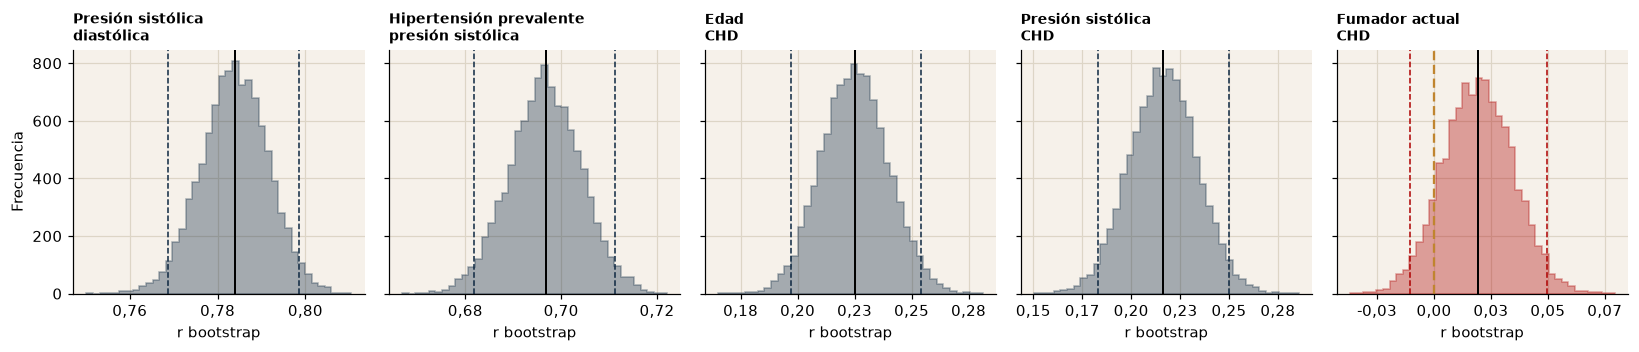

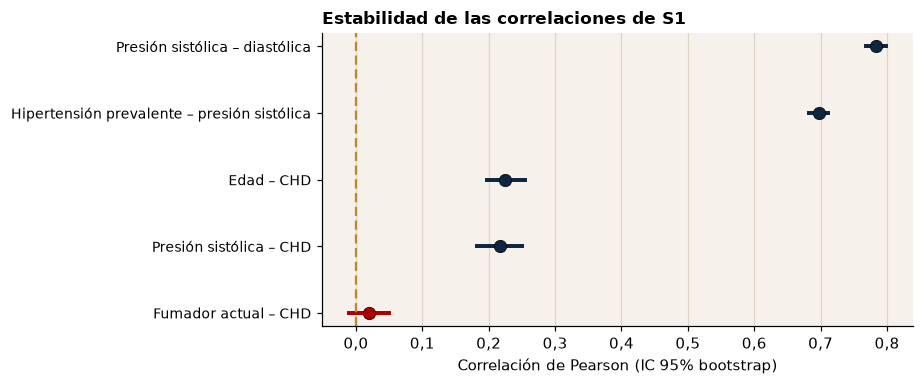

In [12]:
fig, axs = plt.subplots(1, 5, figsize=(15, 3.3), sharey=True)
for ax, (etq, d) in zip(axs, CORR.items()):
    col = RED if d["estado"].startswith("inestable") else NAVY
    ax.hist(d["reps"], bins=40, color=col, alpha=0.35, edgecolor=col, linewidth=1.0, histtype="stepfilled")
    # Cero solo en el panel cuyo intervalo lo contiene, para no comprimir las otras distribuciones.
    if d["lo"] <= 0 <= d["hi"]:
        ax.axvline(0, color=OCHRE, ls=(0, (4, 2)), lw=1.5)
    ax.axvline(d["lo"], color=col, ls="--", lw=1)
    ax.axvline(d["hi"], color=col, ls="--", lw=1)
    ax.axvline(d["r"], color="black", lw=1.3)
    ax.set_title(etq.replace(" – ", "\n"), fontsize=9); ax.set_xlabel("r bootstrap"); eje_es(ax, "x", 2)
axs[0].set_ylabel("Frecuencia")
plt.tight_layout(); plt.savefig(FIGURAS / "fig_corr_distribuciones.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8.5, 3.6))
yy = np.arange(len(CORR))[::-1]
for (etq, d), yv in zip(CORR.items(), yy):
    col = RED if d["estado"].startswith("inestable") else NAVY
    ax.plot([d["lo"], d["hi"]], [yv, yv], color=col, lw=2.6, zorder=2)
    ax.scatter(d["r"], yv, color=col, s=65, zorder=3, edgecolor="black", linewidth=0.5)
ax.axvline(0, color=OCHRE, ls=(0, (4, 2)), lw=1.5)
ax.set_yticks(yy); ax.set_yticklabels(list(CORR.keys()), fontsize=9); ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlación de Pearson (IC 95% bootstrap)"); eje_es(ax, "x", 1)
ax.set_title("Estabilidad de las correlaciones de S1")
plt.tight_layout(); plt.savefig(FIGURAS / "fig_correlaciones.png", bbox_inches="tight"); plt.show()

**Cifras verificadas.** Las estimaciones y los IC percentil al 95 % son:

| Par de S1 | r | IC bootstrap 95 % | Error estándar bootstrap |
|---|---:|---:|---:|
| Presión sistólica–diastólica | 0,784 | [0,769; 0,799] | 0,0077 |
| Hipertensión–presión sistólica | 0,697 | [0,682; 0,711] | 0,0075 |
| Edad–CHD | 0,225 | [0,197; 0,254] | 0,0147 |
| Presión sistólica–CHD | 0,216 | [0,183; 0,250] | 0,0172 |
| Fumador actual–CHD | 0,019 | [-0,011; 0,049] | 0,0154 |

**¿Por qué fumador–CHD se llama «inestable»?** La estimación marginal es muy cercana a cero y su
IC admite asociaciones negativas pequeñas, cero y positivas pequeñas. El 10,02 % de las 10.000 réplicas
es negativo y el 89,98 % positivo: el signo no queda sostenido por el IC al 95 %. Estas fracciones son
frecuencias de remuestreo, no probabilidades de que el parámetro verdadero sea positivo o negativo.
Su amplitud (aproximadamente 0,060) es comparable a edad–CHD (0,057): la diferencia principal es la
cercanía a cero, no una variabilidad excepcional. No se demuestra ausencia de asociación, falta de
aporte predictivo multivariable ni ausencia de efecto causal del tabaquismo.

En los otros cuatro pares todas las réplicas son positivas y sus IC excluyen cero: el signo es estable
bajo este remuestreo. La estabilidad ante outliers se evalúa por separado en §5. La asociación de 0,697
entre hipertensión y presión sistólica aconseja revisar redundancia y colinealidad en S3; no obliga por
sí sola a eliminar una variable. La inferencia sigue dependiendo de independencia entre participantes
y de los casos observados; el bootstrap no resuelve posibles sesgos de selección o faltantes.

## 4. Simulación Monte Carlo basada en parámetros de la Sumativa 1

**Origen de los parámetros.** Se usan exclusivamente tres estimaciones propias de S1, recalculadas
del mismo CSV: $q=P(\mathrm{HTA})$, $p_1=P(\mathrm{CHD}\mid\mathrm{HTA})$ y
$p_0=P(\mathrm{CHD}\mid\mathrm{no\ HTA})$. Proceden del análisis categórico y de la prueba
hipertensión–CHD de S1. Se usa `prevalentHyp` tal como viene codificada: no se redefine con umbrales
clínicos externos. Los tamaños de cohorte, las 10.000 iteraciones y la tolerancia de convergencia son
decisiones de diseño, no nuevos parámetros estimados de otra fuente.

**Cómo se simula una cohorte.** Para cada iteración independiente:
1. Generar $H\sim\mathrm{Binomial}(N,q)$, número de personas con hipertensión.
2. Condicionado a $H$, generar $A\sim\mathrm{Binomial}(H,p_1)$ y
   $C\sim\mathrm{Binomial}(N-H,p_0)$, independientemente: son los casos de CHD en ambos grupos.
3. Calcular la tasa $(A+C)/N$ y el RR $(A/H)/(C/(N-H))$, cuando es estimable, junto con su IC log-normal.

Se generan 10.000 cohortes para cada $N$. La tasa esperada es
$q p_1+(1-q)p_0$ y el RR de referencia es $p_1/p_0$. Esto reproduce un escenario condicionado a S1,
no predice una cohorte externa validada ni modela efectos causales.

In [13]:
rng = np.random.default_rng(SEED)   # sección reproducible
# Solo q, p1 y p0 son parámetros estimados; N y B son decisiones de diseño.
q = df["prevalentHyp"].mean()
p1 = df.loc[df["prevalentHyp"] == 1, TARGET].mean()
p0 = df.loc[df["prevalentHyp"] == 0, TARGET].mean()
teor = q * p1 + (1 - q) * p0
rr_s1 = p1 / p0
tabla_hip = pd.crosstab(df["prevalentHyp"], df[TARGET])
a_, b_, c_, d_ = tabla_hip.loc[1, 1], tabla_hip.loc[1, 0], tabla_hip.loc[0, 1], tabla_hip.loc[0, 0]
se_rr = np.sqrt(1/a_ - 1/(a_+b_) + 1/c_ - 1/(c_+d_))
rr_ic_s1 = np.exp(np.log(rr_s1) + np.array([-1, 1]) * z * se_rr)
print(f"Parámetros de S1: q (hipertensión) = {q:.4f}   p1 (CHD | hipertenso) = {p1:.4f}   p0 (CHD | no hipertenso) = {p0:.4f}")
print(f"Tasa de CHD esperada = q·p1 + (1-q)·p0 = {teor:.4f}   |   riesgo relativo S1 = {rr_s1:.3f}  IC 95% [{rr_ic_s1[0]:.2f}; {rr_ic_s1[1]:.2f}]")
display(pd.DataFrame({
    "Parámetro S1": ["q: prevalencia HTA", "p1: CHD en HTA", "p0: CHD sin HTA"],
    "Numerador": [int(a_+b_), int(a_), int(c_)],
    "Denominador": [len(df), int(a_+b_), int(c_+d_)],
    "Estimación sin redondear": [q,p1,p0],
    "Origen": ["S1: descriptiva categórica", "S1: prueba HTA–CHD", "S1: prueba HTA–CHD"]}))
assert np.isclose(teor, df[TARGET].mean())
assert 0 < q < 1 and 0 < p0 < 1 and 0 < p1 < 1


def simular(N, B, rng):
    nh = rng.binomial(N, q, size=B)                 # hipertensos por cohorte
    a = rng.binomial(nh, p1); c = rng.binomial(N - nh, p0)   # casos de CHD en cada grupo
    b, d = nh - a, (N - nh) - c
    tasa = (a + c) / N
    ok = (a > 0) & (c > 0) & (nh > 0) & (N - nh > 0)
    rr = np.where(ok, (a / np.maximum(nh, 1)) / np.maximum(c / np.maximum(N - nh, 1), 1e-12), np.nan)
    with np.errstate(divide="ignore", invalid="ignore"):
        se = np.sqrt(1/a - 1/nh + 1/c - 1/(N - nh))
        signif = ok & (np.abs(np.log(rr)) > z * se)
    return tasa, rr, signif

N0 = 1000
tasa, rr_sim, sig = simular(N0, B, rng)
run = np.cumsum(tasa) / np.arange(1, B + 1)
mcse = tasa.std(ddof=1) / np.sqrt(B)
UMBRAL = round(teor + 0.03, 3)  # umbral operativo 18,2%; redondeo explícito
print(f"\nN = {N0:,} personas por cohorte, {B:,} cohortes")
print(f"Tasa de CHD simulada: media = {tasa.mean():.4f}  (teórica {teor:.4f}),  sd = {tasa.std(ddof=1):.4f}")
print(f"Error estándar de Monte Carlo de la media = {mcse:.6f}  ({mcse*100:.4f} puntos porcentuales)")
fuera = np.where(np.abs(run - teor) > 0.0005)[0]
conv = int(fuera[-1] + 2) if len(fuera) else 1
print(f"La media acumulada queda dentro de ±0.05 puntos porcentuales del valor teórico desde la cohorte n.° {conv:,}")
print(f"Intervalo central 95% de las tasas entre cohortes = [{np.percentile(tasa, 2.5):.4f}, {np.percentile(tasa, 97.5):.4f}]   P99 = {np.percentile(tasa, 99):.4f}")
print(f"Probabilidad de que una cohorte supere {UMBRAL:.1%} (3 puntos sobre la esperada) = {np.mean(tasa > UMBRAL):.4f}")
print(f"Riesgo relativo simulado: mediana = {np.nanmedian(rr_sim):.3f},  P2.5-P97.5 = [{np.nanpercentile(rr_sim, 2.5):.2f}; {np.nanpercentile(rr_sim, 97.5):.2f}]")
print(f"Cohortes donde la asociación hipertensión–CHD es significativa (IC del RR excluye 1) = {sig.mean():.4f}")
print(f"Variabilidad entre cohortes (SD): {tasa.std(ddof=1)*100:.3f} puntos porcentuales")
print(f"Margen aproximado 95% del error Monte Carlo de la media: ±{z*mcse*100:.4f} puntos porcentuales")
pe = np.mean(tasa > UMBRAL)
print(f"P(tasa > umbral) = {pe:.4f}; MCSE de esta frecuencia = {np.sqrt(pe*(1-pe)/B):.5f}")
display(pd.DataFrame([{"Iteraciones": b, "Media acumulada (%)": tasa[:b].mean()*100,
    "MCSE media (pp)": tasa[:b].std(ddof=1)/np.sqrt(b)*100,
    "Desviación del valor teórico (pp)": (tasa[:b].mean()-teor)*100}
    for b in [100,1000,5000,B]]))


Parámetros de S1: q (hipertensión) = 0.3105   p1 (CHD | hipertenso) = 0.2470   p0 (CHD | no hipertenso) = 0.1092
Tasa de CHD esperada = q·p1 + (1-q)·p0 = 0.1520   |   riesgo relativo S1 = 2.262  IC 95% [1.97; 2.60]


,Parámetro S1,Numerador,Denominador,Estimación sin redondear,Origen
0,q: prevalencia HTA,1316,4238,0.310524,S1: descriptiva categórica
1,p1: CHD en HTA,325,1316,0.246960,S1: prueba HTA–CHD
2,p0: CHD sin HTA,319,2922,0.109172,S1: prueba HTA–CHD



N = 1,000 personas por cohorte, 10,000 cohortes
Tasa de CHD simulada: media = 0.1519  (teórica 0.1520),  sd = 0.0113
Error estándar de Monte Carlo de la media = 0.000113  (0.0113 puntos porcentuales)
La media acumulada queda dentro de ±0.05 puntos porcentuales del valor teórico desde la cohorte n.° 1,743
Intervalo central 95% de las tasas entre cohortes = [0.1300, 0.1740]   P99 = 0.1790
Probabilidad de que una cohorte supere 18.2% (3 puntos sobre la esperada) = 0.0048
Riesgo relativo simulado: mediana = 2.262,  P2.5-P97.5 = [1.69; 3.03]
Cohortes donde la asociación hipertensión–CHD es significativa (IC del RR excluye 1) = 0.9998
Variabilidad entre cohortes (SD): 1.133 puntos porcentuales
Margen aproximado 95% del error Monte Carlo de la media: ±0.0222 puntos porcentuales
P(tasa > umbral) = 0.0048; MCSE de esta frecuencia = 0.00069


,Iteraciones,Media acumulada (%),MCSE media (pp),Desviación del valor teórico (pp)
0,100,15.33400,0.122896,0.138153
1,1000,15.22270,0.037026,0.026853
2,5000,15.18600,0.016181,-0.009847
3,10000,15.19155,0.011332,-0.004297


In [14]:
# Escenarios por tamaño de cohorte (misma semilla por tamaño: cada fila se reproduce por separado)
tamanos = [100, 250, 500, 1000, 4238]
filas, SIMS = [], {}
for N in tamanos:
    r = np.random.default_rng(SEED)
    t, rr, s = simular(N, B, r); SIMS[N] = (t, rr, s)
    lo, hi = np.percentile(t, [2.5, 97.5]); rlo, rhi = np.nanpercentile(rr, [2.5, 97.5])
    filas.append({"N": N, "Tasa media %": t.mean() * 100, "P2.5 tasa %": lo * 100, "P97.5 tasa %": hi * 100,
                  "Ancho (pp)": (hi - lo) * 100, "RR mediano": np.nanmedian(rr), "RR P2.5": rlo, "RR P97.5": rhi,
                  "% cohortes con asociación significativa": s.mean() * 100,
                  "RR válidos": int(np.isfinite(rr).sum()), "RR no estimables": int(np.isnan(rr).sum()),
                  "% RR no estimables": np.isnan(rr).mean()*100})
tabla_mc = pd.DataFrame(filas)
display(tabla_mc.round(2))
print("Referencia S1 (N = 4.238, una sola muestra real): RR = %.2f, IC 95%% [%.2f; %.2f]" % (rr_s1, *rr_ic_s1))
print("Percentiles del RR: solo cohortes con RR estimable. La frecuencia de IC que excluyen 1 usa las B cohortes;")
print("las cohortes no estimables no cuentan como detecciones y se reportan por separado.")


,N,Tasa media %,P2.5 tasa %,P97.5 tasa %,Ancho (pp),RR mediano,RR P2.5,RR P97.5,% cohortes con asociación significativa,RR válidos,RR no estimables,% RR no estimables
0,100,15.19,9.00,23.00,14.00,2.27,0.82,6.53,42.21,9993,7,0.07
1,250,15.21,10.80,19.60,8.80,2.25,1.26,4.15,77.79,10000,0,0.00
2,500,15.21,12.20,18.40,6.20,2.26,1.49,3.43,96.74,10000,0,0.00
3,1000,15.19,13.00,17.40,4.40,2.26,1.69,3.03,99.98,10000,0,0.00
4,4238,15.20,14.11,16.28,2.17,2.26,1.97,2.60,100.00,10000,0,0.00


Referencia S1 (N = 4.238, una sola muestra real): RR = 2.26, IC 95% [1.97; 2.60]
Percentiles del RR: solo cohortes con RR estimable. La frecuencia de IC que excluyen 1 usa las B cohortes;
las cohortes no estimables no cuentan como detecciones y se reportan por separado.


### Figura 4. Distribución simulada y convergencia

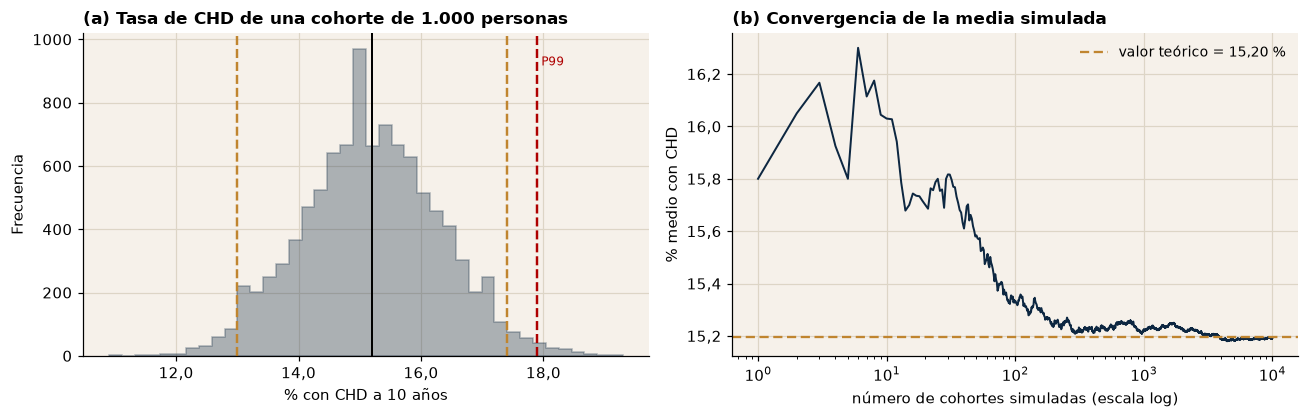

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
p025, p975, p99 = np.percentile(tasa, [2.5, 97.5, 99])
ax[0].hist(tasa * 100, bins=40, color=NAVY, alpha=0.32, edgecolor=NAVY, linewidth=1.0, histtype="stepfilled")
for v, c in [(p025, OCHRE), (p975, OCHRE), (p99, RED)]:
    ax[0].axvline(v * 100, color=c, ls="--", lw=1.6)
ax[0].axvline(teor * 100, color="black", lw=1.3)
ax[0].text(p99 * 100, ax[0].get_ylim()[1] * 0.9, " P99", color=RED, fontsize=8)
ax[0].set_title(f"(a) Tasa de CHD de una cohorte de {N0:,} personas".replace(",", ".")); eje_es(ax[0], "x", 1)
ax[0].set_xlabel("% con CHD a 10 años"); ax[0].set_ylabel("Frecuencia")
ax[1].plot(np.arange(1, B + 1), run * 100, color=NAVY, lw=1.3)
ax[1].axhline(teor * 100, color=OCHRE, ls=(0, (4, 2)), lw=1.5, label=f"valor teórico = {fmt_es(teor*100, 2)} %")
ax[1].set_xscale("log"); ax[1].set_title("(b) Convergencia de la media simulada"); eje_es(ax[1], "y", 1)
ax[1].set_xlabel("número de cohortes simuladas (escala log)"); ax[1].set_ylabel("% medio con CHD")
ax[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(FIGURAS / "fig_montecarlo.png", bbox_inches="tight"); plt.show()

### Figura 5. Efecto del tamaño de la cohorte

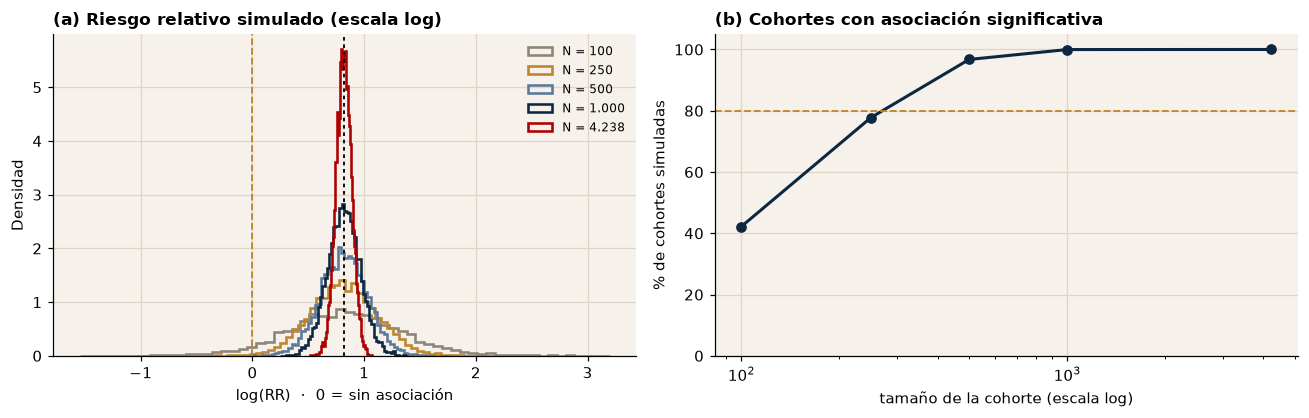

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
cols = {100: GREY, 250: OCHRE, 500: "#5b7a99", 1000: NAVY, 4238: RED}
for N in tamanos:
    ax[0].hist(np.log(SIMS[N][1][~np.isnan(SIMS[N][1])]), bins=60, histtype="step", linewidth=1.7,
               color=cols[N], label=f"N = {N:,}".replace(",", "."), density=True)
ax[0].axvline(np.log(rr_s1), color="black", ls=(0, (2, 2)), lw=1.2); ax[0].axvline(0, color=OCHRE, ls="--", lw=1.2)
ax[0].set_title("(a) Riesgo relativo simulado (escala log)"); ax[0].set_xlabel("log(RR)  ·  0 = sin asociación")
ax[0].set_ylabel("Densidad"); ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(tabla_mc["N"], tabla_mc["% cohortes con asociación significativa"], marker="o", color=NAVY, lw=2)
ax[1].set_xscale("log"); ax[1].set_ylim(0, 105); ax[1].axhline(80, color=OCHRE, ls="--", lw=1.2)
ax[1].set_title("(b) Cohortes con asociación significativa"); ax[1].set_xlabel("tamaño de la cohorte (escala log)")
ax[1].set_ylabel("% de cohortes simuladas")
plt.tight_layout(); plt.savefig(FIGURAS / "fig_montecarlo_N.png", bbox_inches="tight"); plt.show()

**Resultados y cifras verificadas.** Los únicos parámetros estimados son
$q=0,3105238$, $p_1=0,2469605$ y $p_0=0,1091718$; la tasa esperada es 15,19585 % y el RR 2,2621.
Para $N=1.000$, la media de 10.000 tasas es **15,19155 %**. Su intervalo central del 95 % es
[13,0 %; 17,4 %]: describe variación entre cohortes, no un IC del parámetro poblacional.

**Error Monte Carlo frente a variación entre cohortes.** La desviación estándar de las tasas entre
cohortes es **1,13324 puntos porcentuales**. El error estándar Monte Carlo de su media es
$s_{\mathrm{tasas}}/\sqrt{B}$ = **0,0113324 puntos porcentuales**; un margen aproximado del 95 % es
±0,0222 puntos. Aumentar B reduce el error numérico de simulación, pero no la dispersión real entre
cohortes de N personas. Aumentar N sí reduce esa dispersión.

**Convergencia.** En esta ejecución con semilla 42, la media acumulada permanece a menos de
0,05 puntos del valor teórico desde la iteración 1.743. Es un diagnóstico de esta trayectoria, no una
garantía universal de convergencia. El margen Monte Carlo final, menor que esa tolerancia, respalda
10.000 iteraciones para estimar la media con esa precisión; no garantiza igual precisión para colas o RR.
La frecuencia de superar el umbral operativo de 18,2 % es 0,0048 (0,48 %), con MCSE aproximado
0,00069 en escala de probabilidad, equivalente a 0,069 puntos porcentuales.

**Tamaño y casos no estimables.** Los intervalos centrales de las tasas se estrechan al aumentar N.
Para N=100, **7/10.000 cohortes (0,07 %) no permiten estimar el RR con el procedimiento elegido**
por ausencia de grupo o de eventos; sus percentiles [0,82; 6,53] usan solo los 9.993 RR válidos.
En los demás tamaños todos los RR son estimables. La frecuencia de IC que excluyen 1 usa como
denominador las 10.000 cohortes y no cuenta los casos no estimables como detecciones: 42,21 %
para N=100, 77,79 % para 250, 96,74 % para 500, 99,98 % para 1.000 y 100 % para 4.238.
Son frecuencias del escenario simulado, no una garantía de significancia futura.

**Alcance.** Para N=4.238 el intervalo central simulado del RR [1,97; 2,60] es próximo al IC de S1
[1,97; 2,60], lo que muestra coherencia bajo el modelo calibrado, no una validación externa.
q, p1 y p0 se mantienen fijos: no se propaga su incertidumbre de estimación. Se supone independencia
entre personas y se omiten otros factores; la variabilidad adicional de poblaciones reales no está modelada.

## 5. Análisis de robustez

Evaluamos cuánto se mueven los resultados de S1 ante valores extremos y ante supuestos distribucionales: (a) estimadores robustos y jackknife para las medias de las tres variables más asimétricas de S1; (b) sensibilidad de las correlaciones a los outliers y observaciones influyentes (jackknife); (c) la prueba de edad bajo alternativas no paramétricas; y (d) una simulación con distribuciones alternativas que mide la cobertura real del IC clásico cuando la población es asimétrica y de colas pesadas.

In [17]:
# a) Medias de las variables más asimétricas: estimadores robustos y jackknife
def tukey(x):
    q1, q3 = np.percentile(x, [25, 75]); r = q3 - q1
    return (x >= q1 - 1.5 * r) & (x <= q3 + 1.5 * r)
filas, INFL = [], {}
for nombre, col in [("Glucosa (mg/dL)", "glucose"), ("Colesterol total (mg/dL)", "totChol"), ("Presión sistólica (mmHg)", "sysBP")]:
    s = df[col].dropna(); x = s.to_numpy(float); nn = len(x)
    media = x.mean(); rec5 = stats.trim_mean(x, 0.05); sin_t = x[tukey(x)].mean(); med = np.median(x)
    jk = (x.sum() - x) / (nn - 1)
    se_jk = np.sqrt((nn - 1) / nn * ((jk - jk.mean()) ** 2).sum()); se_cl = x.std(ddof=1) / np.sqrt(nn)
    infl = np.abs(jk - media); top = np.argsort(infl)[::-1][:3]
    INFL[col] = [(int(s.index[i]), float(x[i]), float(infl[i])) for i in top]
    filas.append({"Variable": nombre, "Media": media, "Recortada 5%": rec5, "Sin outliers (Tukey)": sin_t, "Mediana": med,
                  "Cambio al recortar (%)": 100 * (rec5 - media) / media, "% outliers Tukey": 100 * (1 - tukey(x).mean()),
                  "SE clásico": se_cl, "SE jackknife": se_jk, "Obs. más influyente (valor)": x[top[0]],
                  "Efecto máx. de 1 obs. en la media": infl[top[0]]})
tabla_rob_media = pd.DataFrame(filas)
display(tabla_rob_media.round(3))

# IC de la media de glucosa (variable más asimétrica): clásico, percentil y BCa
rng = np.random.default_rng(SEED)
xg = df["glucose"].dropna().to_numpy(float); mg, lg, hg = ic_t(xg)
rg = replicas(xg, np.mean, B, rng); bcg, z0g, ag = ic_bca(mg, rg, jackknife(xg, np.mean))
print(f"\nGlucosa media = {mg:.3f}")
print(f"  clásico   [{lg:.3f}, {hg:.3f}]")
print(f"  percentil [{ic_percentil(rg)[0]:.3f}, {ic_percentil(rg)[1]:.3f}]")
print(f"  BCa       [{bcg[0]:.3f}, {bcg[1]:.3f}]   (z0 = {z0g:+.3f}, a = {ag:+.5f})")

,Variable,Media,Recortada 5%,Sin outliers (Tukey),Mediana,Cambio al recortar (%),% outliers Tukey,SE clásico,SE jackknife,Obs. más influyente (valor),Efecto máx. de 1 obs. en la media
0,Glucosa (mg/dL),81.967,79.441,78.490,78.0,-3.082,4.883,0.386,0.386,394.0,0.081
1,Colesterol total (mg/dL),236.722,235.193,234.893,234.0,-0.646,1.337,0.689,0.689,696.0,0.110
2,Presión sistólica (mmHg),132.352,130.906,130.302,128.0,-1.093,2.973,0.339,0.339,295.0,0.038



Glucosa media = 81.967
  clásico   [81.210, 82.724]
  percentil [81.243, 82.733]
  BCa       [81.278, 82.787]   (z0 = +0.032, a = +0.01668)


In [18]:
# b) Correlaciones: efecto de los outliers y observaciones influyentes (jackknife)
def r_sin_una(x, yv):
    """Correlación dejando fuera cada observación (jackknife), en forma vectorizada."""
    m = len(x); sx, sy, sxx, syy, sxy = x.sum(), yv.sum(), (x**2).sum(), (yv**2).sum(), (x*yv).sum()
    mx, my = m - 1, m - 1
    num = (sxy - x*yv) - (sx - x) * (sy - yv) / (m - 1)
    vx = (sxx - x**2) - (sx - x) ** 2 / (m - 1); vy = (syy - yv**2) - (sy - yv) ** 2 / (m - 1)
    return num / np.sqrt(vx * vy)

filas, INFL_CORR = [], {}
for c1, c2, etq in PARES[:4]:
    s = df[[c1, c2]].dropna(); x, yv = s[c1].to_numpy(float), s[c2].to_numpy(float)
    r0 = np.corrcoef(x, yv)[0, 1]
    ok = tukey(x) & (tukey(yv) if len(np.unique(yv)) > 2 else True)
    r_sin = np.corrcoef(x[ok], yv[ok])[0, 1]
    rj = r_sin_una(x, yv); dj = np.abs(rj - r0); i = int(np.argmax(dj))
    INFL_CORR[etq] = (int(s.index[i]), float(dj[i]))
    filas.append({"Correlación": etq, "r (S1)": r0, "r sin outliers (Tukey)": r_sin, "Cambio": r_sin - r0,
                  "Filas excluidas": int((~ok).sum()), "Mín. r jackknife": rj.min(), "Máx. r jackknife": rj.max(),
                  "Efecto máx. de 1 fila": dj[i]})
tabla_rob_corr = pd.DataFrame(filas)
display(tabla_rob_corr.round(4))

# Los atípicos de presión sistólica: ¿errores o pacientes de alto riesgo?
pas = df[["sysBP", TARGET]].dropna(); ok_pas = tukey(pas["sysBP"].to_numpy(float))
print(f"Atípicos de presión sistólica: {(~ok_pas).sum()}, todos sobre el límite superior: {bool((pas.loc[~ok_pas, 'sysBP'] > pas['sysBP'].median()).all())}")
print(f"  % CHD en atípicos = {pas.loc[~ok_pas, TARGET].mean()*100:.1f}%   global = {pas[TARGET].mean()*100:.1f}%")
print(f"  DE de la presión sistólica: completa = {pas['sysBP'].std():.1f}, sin atípicos = {pas.loc[ok_pas, 'sysBP'].std():.1f} mmHg (restricción de rango)")
print(f"  Spearman presión sistólica–CHD (basada en rangos) = {stats.spearmanr(pas['sysBP'], pas[TARGET])[0]:.3f}")

,Correlación,r (S1),r sin outliers (Tukey),Cambio,Filas excluidas,Mín. r jackknife,Máx. r jackknife,Efecto máx. de 1 fila
0,Presión sistólica – diastólica,0.7840,0.7531,-0.0309,162,0.7827,0.7860,0.0020
1,Hipertensión prevalente – presión sistólica,0.6968,0.6974,0.0007,126,0.6966,0.6988,0.0021
2,Edad – CHD,0.2253,0.2253,0.0000,0,0.2242,0.2264,0.0012
3,Presión sistólica – CHD,0.2164,0.1812,-0.0352,126,0.2138,0.2179,0.0026


Atípicos de presión sistólica: 126, todos sobre el límite superior: True
  % CHD en atípicos = 39.7%   global = 15.2%
  DE de la presión sistólica: completa = 22.0, sin atípicos = 18.8 mmHg (restricción de rango)
  Spearman presión sistólica–CHD (basada en rangos) = 0.194


In [19]:
# c) Prueba de edad (S1) bajo alternativas: t de Student, Welch, Mann-Whitney y permutación
edad1, edad0 = edad[y == 1], edad[y == 0]
stud = stats.ttest_ind(edad1, edad0)
mw = stats.mannwhitneyu(edad1, edad0, alternative="two-sided")
auc_mw = mw.statistic / (len(edad1) * len(edad0))
tabla_prueba = pd.DataFrame({
    "Prueba": ["t de Welch (S1)", "t de Student", "Mann-Whitney (no paramétrica)", "Permutación (diferencia de medias)"],
    "Estadístico": [welch.statistic, stud.statistic, mw.statistic, obs_dif],
    "Valor p": [welch.pvalue, stud.pvalue, mw.pvalue, p_dif]})
display(tabla_prueba)
print(f"P(edad de un caso con CHD > edad de uno sin CHD) = {auc_mw:.3f} (0,5 = sin diferencia)")
a1, a0 = np.asarray(edad1), np.asarray(edad0)
print(f"  estrictamente mayor = {(a1[:, None] > a0[None, :]).mean():.3f}; pares empatados = {(a1[:, None] == a0[None, :]).mean():.3f} (Mann-Whitney los cuenta como mitad)")

,Prueba,Estadístico,Valor p
0,t de Welch (S1),1.557681e+01,1.040617e-48
1,t de Student,1.504742e+01,6.845009e-50
2,Mann-Whitney (no paramétrica),1.571718e+06,1.165855e-47
3,Permutación (diferencia de medias),5.378294e+00,9.999000e-05


P(edad de un caso con CHD > edad de uno sin CHD) = 0.679 (0,5 = sin diferencia)
  estrictamente mayor = 0.665; pares empatados = 0.029 (Mann-Whitney los cuenta como mitad)


In [20]:
# d) Distribuciones alternativas: ¿cuánto cubre realmente el IC clásico al 95%?
# Población 1: lognormal con la media y desviación de la glucosa estimadas en S1.
# Población 2: la distribución empírica de la glucosa de S1 (colas muy pesadas, curtosis alta).
rng = np.random.default_rng(SEED)
gl = df["glucose"].dropna().to_numpy(float)
m_s1, s_s1 = gl.mean(), gl.std(ddof=1)
sig2 = np.log(1 + (s_s1 / m_s1) ** 2); mu = np.log(m_s1) - sig2 / 2
POBS = {"Lognormal (media y sd de S1)": (lambda b, nn: rng.lognormal(mu, np.sqrt(sig2), size=(b, nn)), np.exp(mu + sig2 / 2)),
        "Empírica de S1 (colas pesadas)": (lambda b, nn: gl[rng.integers(0, len(gl), size=(b, nn))], gl.mean())}
print(f"Glucosa S1: asimetría = {stats.skew(gl):.2f}, curtosis en exceso = {stats.kurtosis(gl):.2f}  "
      f"| lognormal ajustada: asimetría = {(np.exp(sig2)+2)*np.sqrt(np.exp(sig2)-1):.2f}")
REPS_COB = 10_000
filas = []
for nombre_p, (muestrear, verdadera) in POBS.items():
    for nn in [30, 100, 500, 3850]:
        cubre = 0; bajo = 0; ancho = 0.0
        for i in range(0, REPS_COB, 500):
            xs = muestrear(500, nn); m = xs.mean(1); se = xs.std(1, ddof=1) / np.sqrt(nn)
            h = stats.t.ppf(0.975, nn - 1) * se
            cubre += np.sum((m - h <= verdadera) & (verdadera <= m + h)); bajo += np.sum(verdadera < m - h); ancho += (2 * h).sum()
        filas.append({"Población": nombre_p, "n": nn, "Cobertura real (%)": 100 * cubre / REPS_COB,
                      "IC por encima del valor verdadero (%)": 100 * bajo / REPS_COB,
                      "IC por debajo del valor verdadero (%)": 100 * (REPS_COB - cubre - bajo) / REPS_COB,
                      "Ancho medio del IC": ancho / REPS_COB})
tabla_cob = pd.DataFrame(filas)
tabla_cob.round(2)

Glucosa S1: asimetría = 6.21, curtosis en exceso = 58.60  | lognormal ajustada: asimetría = 0.90


,Población,n,Cobertura real (%),IC por encima del valor verdadero (%),IC por debajo del valor verdadero (%),Ancho medio del IC
0,Lognormal (media y sd de S1),30,94.75,1.40,3.85,17.69
1,Lognormal (media y sd de S1),100,94.95,1.79,3.26,9.47
2,Lognormal (media y sd de S1),500,94.81,2.37,2.82,4.21
3,Lognormal (media y sd de S1),3850,95.15,2.28,2.57,1.51
4,Empírica de S1 (colas pesadas),30,88.01,0.11,11.88,15.00
5,Empírica de S1 (colas pesadas),100,89.06,0.31,10.63,8.89
6,Empírica de S1 (colas pesadas),500,93.54,0.81,5.65,4.16
7,Empírica de S1 (colas pesadas),3850,94.53,1.69,3.78,1.51


In [21]:
# ¿Por qué la glucosa tiene colas pesadas? Mezcla de no diabéticos y diabéticos
gd = df[["glucose", "diabetes"]].dropna()
def forma(v):
    return {"n": len(v), "Media": v.mean(), "Mediana": np.median(v),
            "Asimetría": stats.skew(v), "Curtosis en exceso": stats.kurtosis(v)}
tabla_colas = pd.DataFrame({
    "Total": forma(gl),
    "No diabéticos": forma(gd.loc[gd["diabetes"] == 0, "glucose"].to_numpy(float)),
    "Diabéticos": forma(gd.loc[gd["diabetes"] == 1, "glucose"].to_numpy(float)),
    "Sin valores >= 200": forma(gl[gl < 200]),
    "log(glucosa)": forma(np.log(gl)),
}).T
display(tabla_colas.round(2))
z4 = ((gl - gl.mean()) / gl.std()) ** 4
alto = gl >= 200
print(f"Diabéticos entre quienes tienen glucosa: {gd['diabetes'].mean()*100:.1f}%")
print(f"Registros con glucosa >= 200 mg/dL: {alto.sum()} (diabéticos: {int(gd.loc[gd['glucose'] >= 200, 'diabetes'].sum())})")
print(f"Aporte de esos registros a la suma de z^4 que define la curtosis: {z4[alto].sum() / z4.sum() * 100:.1f}%")
print(f"Probabilidad de que una muestra de n = 30 no contenga ninguno: {(1 - alto.mean()) ** 30:.3f}")
print(f"Percentil 99 de la glucosa: {np.percentile(gl, 99):.0f} mg/dL")

,n,Media,Mediana,Asimetría,Curtosis en exceso
Total,3850.0,81.97,78.00,6.21,58.60
No diabéticos,3745.0,79.49,78.00,1.00,2.45
Diabéticos,105.0,170.33,145.00,0.93,0.16
Sin valores >= 200,3816.0,80.27,78.00,1.84,7.60
log(glucosa),3850.0,4.38,4.36,2.25,12.00


Diabéticos entre quienes tienen glucosa: 2.7%
Registros con glucosa >= 200 mg/dL: 34 (diabéticos: 34)
Aporte de esos registros a la suma de z^4 que define la curtosis: 97.7%
Probabilidad de que una muestra de n = 30 no contenga ninguno: 0.766
Percentil 99 de la glucosa: 175 mg/dL


**Lectura.**

**a) Valores extremos en las medias.** La media recortada al 5 % por cola baja 3,1 % en la glucosa (de 81,97 a 79,44 mg/dL; 4,9 % de valores atípicos según Tukey), 0,6 % en el colesterol y 1,1 % en la presión sistólica. Sin atípicos, la media de glucosa (78,49) se acerca a su mediana (78,0): para describir el valor típico conviene la mediana. El jackknife muestra que la observación más influyente cambia la media en solo 0,08, 0,11 y 0,04 unidades (hasta 0,2 errores estándar), así que ningún caso aislado determina el resultado. Su error estándar coincide con el clásico (glucosa 0,386; colesterol 0,689; presión sistólica 0,339), pero en la media eso ocurre por construcción y no aporta evidencia adicional. En la glucosa, el BCa [81,28; 82,79] se desplaza 0,07 respecto del clásico [81,21; 82,72] (aceleración 0,017, la mayor de todas), aún sin consecuencias prácticas.

**b) Correlaciones.** Al excluir los valores atípicos de Tukey, presión sistólica con CHD baja de 0,22 a 0,18 (126 filas excluidas) y presión sistólica con diastólica de 0,78 a 0,75 (162 filas); la de hipertensión con presión sistólica y la de edad con CHD no cambian. Los 126 atípicos de presión sistólica son todos valores altos, plausibles y de alto riesgo (39,7 % con CHD frente a 15,2 %): al quitarlos se restringe el rango (desviación de 22,0 a 18,8 mmHg) y la correlación baja casi por construcción, mientras la de Spearman, basada en rangos, es 0,19. Esos extremos **aportan parte de la señal real; no la inflan**. Ninguna observación individual altera una correlación en más de 0,003, así que no hay un caso dominante.

**c) Prueba de edad.** t de Student (p = 6,8 × 10⁻⁵⁰), Welch (1,0 × 10⁻⁴⁸), Mann-Whitney (1,2 × 10⁻⁴⁷) y permutación (p = 0,0001, la cota mínima 1/(B+1)) llevan a la misma decisión. Según Mann-Whitney, la probabilidad de que una persona con CHD sea mayor que una sin CHD es 0,68 contando los empates como mitad (0,665 si solo se cuentan los pares estrictamente mayores; el 2,9 % de los pares empata). La conclusión no depende de la distribución supuesta.

**d) Distribuciones alternativas.** Con una población lognormal con la media y desviación de la glucosa de S1 (asimetría 0,90), el IC clásico cubre entre 94,8 % y 95,2 % desde n = 30 hasta 3.850. Con la distribución empírica de la glucosa (asimetría 6,2 y curtosis 58,6, colas muy pesadas) la cobertura real cae a 88,0 % con n = 30 y 89,1 % con n = 100, sube a 93,5 % con n = 500 y llega a 94,5 % con n = 3.850 (error de simulación de ±0,4 puntos); además los intervalos fallan casi siempre hacia abajo. **¿Por qué las colas pesadas?** La glucosa es una mezcla: el 97,3 % no diabético se distribuye casi simétrico (asimetría 1,0; curtosis 2,5), mientras el 2,7 % diabético tiene una media de 170 mg/dL y llega a 394. Los 34 registros de 200 mg/dL o más, todos de diabéticos, aportan el 97,7 % de la suma que define la curtosis; sin ellos, la curtosis baja de 58,6 a 7,6. Con n = 30, el 77 % de las muestras no contiene ninguno de esos valores, por lo que su media y su desviación quedan bajas y el intervalo falla hacia abajo. El logaritmo atenúa pero no resuelve el problema (asimetría 2,25; curtosis 12,0). Esto confirma que el TCL depende del tamaño de muestra y del peso de las colas, no solo de la asimetría: con el n de S1 el IC de la glucosa es confiable; con muestras de 100 o menos habría sido demasiado optimista.

**Síntesis: qué es confiable y qué requiere cautela.**
- **Confiable:** los IC de edad, colesterol y presión sistólica medias y de la proporción de CHD; las dos pruebas de hipótesis (edad e hipertensión); y las correlaciones presión sistólica–diastólica, hipertensión–presión sistólica y edad–CHD.
- **Con cautela:** la media de glucosa como valor típico (usar la mediana); la magnitud de las correlaciones con presión sistólica, que depende de sus valores altos; la correlación fumador–CHD, indistinguible de cero; y el IC de la mediana, toscamente discreto.
- **Supuesto sin verificar:** la independencia entre participantes, de la que dependen todos los métodos usados.

## 6. Reporte de resultados validados para la Sumativa 3

Se consolidan los parámetros robustamente estimados, las correlaciones estables, las observaciones influyentes y las recomendaciones metodológicas. La tabla se guarda como archivo de resultados validados en la carpeta de esta evaluación.

In [22]:
def estado_ic(c):
    p = PARAMS[c]; bt = BOOT[c]
    ref = (p["lo"], p["hi"]) if not np.isnan(p["lo"]) else bt["pc"]
    dmax = max(abs(bt["bc"][0] - ref[0]), abs(bt["bc"][1] - ref[1])) / (ref[1] - ref[0])
    return dmax
esc = {"chd": 100}
filas = []
for c in ["edad", "colesterol", "pas", "chd"]:
    p, bt = PARAMS[c], BOOT[c]; e = esc.get(c, 1); d = estado_ic(c)
    filas.append({"Resultado de S1": p["nombre"], "Valor S1": f"{p['est']*e:.2f}",
                  "IC clásico S1": f"[{p['lo']*e:.2f}; {p['hi']*e:.2f}]", "Evidencia S2 (IC o p)": f"[{bt['bc'][0]*e:.2f}; {bt['bc'][1]*e:.2f}]",
                  "Veredicto": "Robusto" if d < 0.05 else "Usar con cautela", "Evidencia": f"BCa difiere {100*d:.1f}% de la amplitud del IC clásico"})
filas.append({"Resultado de S1": "Mediana del colesterol", "Valor S1": f"{PARAMS['mediana_col']['est']:.2f}", "IC clásico S1": "—",
              "Evidencia S2 (IC o p)": f"[{BOOT['mediana_col']['bc'][0]:.2f}; {BOOT['mediana_col']['bc'][1]:.2f}]",
              "Veredicto": "Usar con cautela",
              "Evidencia": "Sin fórmula clásica; IC percentil [%.0f; %.0f] y BCa toscos: el colesterol se mide en enteros y la mediana toma pocos valores"
                           % tuple(BOOT["mediana_col"]["pc"])})
rob_g = tabla_rob_media.set_index("Variable").loc["Glucosa (mg/dL)"]
cob_g = tabla_cob[tabla_cob["Población"].str.startswith("Empírica")].set_index("n")["Cobertura real (%)"]
filas.append({"Resultado de S1": "Glucosa media (mg/dL)", "Valor S1": f"{mg:.2f}", "IC clásico S1": f"[{lg:.2f}; {hg:.2f}]",
              "Evidencia S2 (IC o p)": f"[{bcg[0]:.2f}; {bcg[1]:.2f}] (BCa)", "Veredicto": "Usar con cautela",
              "Evidencia": f"Media recortada al 5% por cola = {rob_g['Recortada 5%']:.2f}; cobertura del IC clásico "
                           f"{cob_g[30]:.1f}% con n = 30 y {cob_g[100]:.1f}% con n = 100"})
filas.append({"Resultado de S1": "Prueba 1: edad y CHD (Welch)", "Valor S1": f"dif. = {obs_dif:.2f} años", "IC clásico S1": f"p = {welch.pvalue:.1e}",
              "Evidencia S2 (IC o p)": f"p perm. = {p_dif:.4f} (0 de {B:,} permutaciones igualan lo observado)".replace(",", "."),
              "Veredicto": "Robusto", "Evidencia": "Permutación, Mann-Whitney y Student concuerdan; la nula permutada reproduce la t teórica"})
filas.append({"Resultado de S1": "Prueba 2: hipertensión y CHD (χ²)", "Valor S1": f"χ² = {chi_yates[0]:.1f}", "IC clásico S1": f"p = {chi_yates[1]:.1e}",
              "Evidencia S2 (IC o p)": f"p perm. = {p_chi:.4f}", "Veredicto": "Robusto",
              "Evidencia": f"RR simulado reproducible (N = 4.238: significativo en {SIMS[4238][2].mean()*100:.0f}% de cohortes)"})
mc = tabla_mc.set_index("N").loc[4238]
filas.append({"Resultado de S1": "RR hipertensión y CHD (Monte Carlo)", "Valor S1": f"RR = {rr_s1:.2f}",
              "IC clásico S1": f"[{rr_ic_s1[0]:.2f}; {rr_ic_s1[1]:.2f}]",
              "Evidencia S2 (IC o p)": f"[{mc['RR P2.5']:.2f}; {mc['RR P97.5']:.2f}] (10.000 cohortes, N = 4.238)",
              "Veredicto": "Coherente", "Evidencia": "Intervalo central de cohortes simuladas con parámetros de S1; no es validación externa"})
r_sin = tabla_rob_corr.set_index("Correlación")["r sin outliers (Tukey)"]
for etq, d in CORR.items():
    if d["estado"] != "robusta":
        ver, evid = "Inestable (sin efecto distinguible de cero)", "IC bootstrap incluye el cero"
    elif etq in r_sin and abs(r_sin[etq] - d["r"]) / abs(d["r"]) >= 0.10:   # cambio relativo de 10% o más
        ver = "Signo robusto; magnitud con cautela"
        evid = f"IC bootstrap no incluye el cero; r = {r_sin[etq]:.3f} sin los valores atípicos (Tukey)"
    else:
        ver, evid = "Robusto", "IC bootstrap no incluye el cero"
    filas.append({"Resultado de S1": f"Correlación {etq}", "Valor S1": f"r = {d['r']:.3f}", "IC clásico S1": "—",
                  "Evidencia S2 (IC o p)": f"[{d['lo']:.3f}; {d['hi']:.3f}] (bootstrap percentil)",
                  "Veredicto": ver, "Evidencia": evid})
reporte = pd.DataFrame(filas)
display(reporte)
reporte.to_csv(SALIDA / "resultados_validados.csv", index=False, encoding="utf-8")

infl = pd.DataFrame([{"Variable o correlación": k, "Índice pandas": v[0], "Valor": v[1], "Efecto sobre el estadístico": v[2]}
                     for k, vs in INFL.items() for v in vs[:1]] +
                    [{"Variable o correlación": f"r {k}", "Índice pandas": v[0], "Valor": np.nan, "Efecto sobre el estadístico": v[1]}
                     for k, v in INFL_CORR.items()])
infl.insert(2, "Línea en framingham.csv", infl["Índice pandas"] + 2)   # +1 por el encabezado y +1 porque el índice parte en 0
display(infl.round(4))
ids = sorted({v[0] for vs in INFL.values() for v in vs[:1]} | {v[0] for v in INFL_CORR.values()})
print("Características de las filas más influyentes:")
display(df.loc[ids, ["age", "male", "sysBP", "diaBP", "prevalentHyp", "totChol", "glucose", "diabetes", TARGET]])
infl.to_csv(SALIDA / "observaciones_influyentes.csv", index=False, encoding="utf-8")
print("Guardados:", sorted(f.name for f in SALIDA.glob("*.csv")))

,Resultado de S1,Valor S1,IC clásico S1,Evidencia S2 (IC o p),Veredicto,Evidencia
0,Edad media (años),49.58,[49.33; 49.84],[49.33; 49.85],Robusto,BCa difiere 0.8% de la amplitud del IC clásico
1,Colesterol total medio (mg/dL),236.72,[235.37; 238.07],[235.41; 238.08],Robusto,BCa difiere 1.3% de la amplitud del IC clásico
2,Presión sistólica media (mmHg),132.35,[131.69; 133.02],[131.71; 133.03],Robusto,BCa difiere 1.4% de la amplitud del IC clásico
3,Proporción de CHD a 10 años,15.20,[14.15; 16.31],[14.13; 16.30],Robusto,BCa difiere 0.6% de la amplitud del IC clásico
4,Mediana del colesterol,234.00,—,[232.00; 236.00],Usar con cautela,Sin fórmula clásica; IC percentil [232; 235] y...
5,Glucosa media (mg/dL),81.97,[81.21; 82.72],[81.28; 82.79] (BCa),Usar con cautela,Media recortada al 5% por cola = 79.44; cobert...
6,Prueba 1: edad y CHD (Welch),dif. = 5.38 años,p = 1.0e-48,p perm. = 0.0001 (0 de 10.000 permutaciones ig...,Robusto,"Permutación, Mann-Whitney y Student concuerdan..."
7,Prueba 2: hipertensión y CHD (χ²),χ² = 132.6,p = 1.1e-30,p perm. = 0.0001,Robusto,RR simulado reproducible (N = 4.238: significa...
8,RR hipertensión y CHD (Monte Carlo),RR = 2.26,[1.97; 2.60],"[1.97; 2.60] (10.000 cohortes, N = 4.238)",Coherente,Intervalo central de cohortes simuladas con pa...
9,Correlación Presión sistólica – diastólica,r = 0.784,—,[0.769; 0.799] (bootstrap percentil),Robusto,IC bootstrap no incluye el cero


,Variable o correlación,Índice pandas,Línea en framingham.csv,Valor,Efecto sobre el estadístico
0,glucose,2909,2911,394.0,0.0811
1,totChol,3160,3162,696.0,0.1097
2,sysBP,481,483,295.0,0.0384
3,r Presión sistólica – diastólica,2197,2199,NaN,0.0020
4,r Hipertensión prevalente – presión sistólica,481,483,NaN,0.0021
5,r Edad – CHD,781,783,NaN,0.0012
6,r Presión sistólica – CHD,481,483,NaN,0.0026


Características de las filas más influyentes:


,age,male,sysBP,diaBP,prevalentHyp,totChol,glucose,diabetes,TenYearCHD
481,64,0,295.0,135.0,1,253.0,70.0,0,1
781,35,1,112.0,62.5,0,175.0,69.0,0,1
2197,63,0,193.0,63.0,1,293.0,76.0,0,1
2909,67,0,204.0,96.0,1,303.0,394.0,1,1
3160,51,1,157.0,87.0,1,696.0,84.0,0,0


Guardados: ['observaciones_influyentes.csv', 'resultados_validados.csv']


**Recomendaciones metodológicas para la Sumativa 3.**
1. **Predictoras estables:** edad y presión sistólica tienen asociación con el CHD estable (r ≈ 0,22; IC lejos del cero). Hipertensión prevalente y presión sistólica están correlacionadas de forma estable (r ≈ 0,70), por lo que conviene elegir una de las dos o verificar el VIF al incluirlas juntas.
2. **Tabaquismo:** la correlación lineal marginal con el CHD no se distingue de cero (r ≈ 0,02). Eso no permite concluir que no aporte en un modelo multivariable, así que debe evaluarse allí y no descartarse de antemano.
3. **Valores extremos:** no eliminarlos, porque son clínicamente plausibles (S1). En la glucosa (asimetría 6,2 y curtosis 58,6) el logaritmo no basta: deja asimetría 2,25 y curtosis 12,0. Conviene acotarla al percentil 99 (175 mg/dL) antes de estandarizar y, si entra junto a `diabetes` (r = 0,62), verificar el VIF.
4. **Observaciones influyentes:** los registros 481 (presión sistólica de 295 mmHg; influye en tres resultados), 2909 (glucosa 394), 3160 (colesterol 696), 2197 y 781 deben registrarse. Son índices de pandas, que parten en 0; la línea en `framingham.csv` es el índice + 2. Se recomienda ajustar los modelos con y sin ellos y reportar si cambian los coeficientes.
5. **Incertidumbre del desempeño:** con una prevalencia de 15,2 %, un conjunto de prueba del 30 % tiene alrededor de 190 casos de CHD, y la simulación muestra cuánto fluctúan las tasas en muestras de ese tamaño. Se sugiere partición estratificada, validación cruzada repetida e IC bootstrap para AUC, sensibilidad y precisión.
6. **Faltantes:** la glucosa (9,2 %) es la variable con más datos faltantes; imputar con la mediana calculada solo en el conjunto de entrenamiento para no filtrar información al de prueba.

Los resultados de la tabla anterior y las observaciones influyentes quedan guardados en `resultados_validados.csv` y `observaciones_influyentes.csv`, en la carpeta de esta evaluación.

In [23]:
print("Figuras generadas:", sorted(f.name for f in FIGURAS.glob("*.png")))

Figuras generadas: ['fig_bootstrap.png', 'fig_corr_distribuciones.png', 'fig_correlaciones.png', 'fig_montecarlo.png', 'fig_montecarlo_N.png', 'fig_permutacion.png']
